In [4]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
url = "https://raw.githubusercontent.com/deepakorani/Supermarket-Sales-Kaggle-Dataset/main/supermarket_sales.csv"
df = pd.read_csv(url)

In [6]:
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


# 1. Data importing 

In [7]:

# 5. Dataset Shape

print("Dataset Shape:", df.shape)


# 6. Column Names

print("\nColumn Names:")
print(df.columns.tolist())


# 7. Dataset Information

print("\nDataset Information:")
df.info()


# 8. Numerical Columns

numerical_columns = df.select_dtypes(include=np.number).columns

print("\nNumerical Columns:")
print(numerical_columns.tolist())


# 9. Categorical Columns

categorical_columns = df.select_dtypes(include='object').columns

print("\nCategorical Columns:")
print(categorical_columns.tolist())


# 10. Statistical Summary of Numerical Columns

display(df.describe())


# 11. Statistical Summary of Categorical Columns

display(df.describe(include='object'))


# 12. Dataset Overview

print("\nDataset Overview:")
print("Total Records:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Memory Usage:", round(df.memory_usage(deep=True).sum() / 1024, 2), "KB")

Dataset Shape: (1000, 17)

Column Names:
['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Date', 'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income', 'Rating']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Total                  

,Unit price,Quantity,Tax 5%,Total,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1.000000e+03,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905e+00,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,6.131498e-14,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905e+00,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905e+00,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905e+00,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905e+00,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905e+00,49.650000,10.00000


,Invoice ID,Branch,City,Customer type,Gender,Product line,Date,Time,Payment
count,1000,1000,1000,1000,1000,1000,1000,1000,1000
unique,1000,3,3,2,2,6,89,506,3
top,750-67-8428,A,Yangon,Member,Female,Fashion accessories,2/7/2019,19:48,Ewallet
freq,1,340,340,501,501,178,20,7,345



Dataset Overview:
Total Records: 1000
Total Columns: 17
Memory Usage: 561.73 KB


# 2. Data cleaning 

In [8]:
# 1. Check Missing Values

print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())


# 2. Handle Missing Values

# Check missing values before handling them
if df.isnull().sum().sum() > 0:

    numerical_columns = df.select_dtypes(include=np.number).columns
    categorical_columns = df.select_dtypes(include='object').columns

    for col in numerical_columns:
        df[col] = df[col].fillna(df[col].median())

    for col in categorical_columns:
        df[col] = df[col].fillna(df[col].mode()[0])

else:
    print("\nNo missing values found. No action required.")


# 3. Check Duplicate Records

print("\nDuplicate Records:", df.duplicated().sum())


# 4. Remove Duplicate Records

df.drop_duplicates(inplace=True)

print("Duplicates After Removal:", df.duplicated().sum())


# 5. Check Data Types

print("\nData Types Before Correction:")
print(df.dtypes)


# 6. Correct Data Types

df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

df['Time'] = pd.to_datetime(df['Time'], format='%H:%M', errors='coerce').dt.time


print("\nData Types After Correction:")
print(df.dtypes)


# 7. Check Invalid and Inconsistent Values

print("\nUnique Values in Categorical Columns:")

for col in df.select_dtypes(include='object').columns:
    print(f"\n{col}:")
    print(df[col].unique())


# 8. Check Invalid Numerical Values

print("\nInvalid Numerical Values:")

print("Quantity <= 0:", (df['Quantity'] <= 0).sum())
print("Unit Price <= 0:", (df['Unit price'] <= 0).sum())
print("Rating Outside 0-10:", (~df['Rating'].between(0, 10)).sum())


# 9. Verify Dataset After Cleaning

print("\nFinal Dataset Verification:")

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nFinal Data Types:")
print(df.dtypes)

Missing Values:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64

Total Missing Values: 0

No missing values found. No action required.

Duplicate Records: 0
Duplicates After Removal: 0

Data Types Before Correction:
Invoice ID                  object
Branch                      object
City                        object
Customer type               object
Gender                      object
Product line                object
Unit price                 float64
Quantity                     int64
Tax 5%                     float64
Total      

#### . Interpretation:::::

The dataset contained no missing values or duplicate records, so no imputation or duplicate removal was required. The Date and Time columns were converted into appropriate data types, and numerical and categorical features were checked for invalid or inconsistent values.

# q. why we follow specific techniques for cleaning ?
ANSWER. No missing values or duplicate records were found, so no rows were filled or removed. The Date and Time columns were converted into appropriate data types. Numerical and categorical columns were checked for invalid or inconsistent values, and the dataset was verified after cleaning to ensure data quality.

In [9]:
%matplotlib inline

# 3 . FEATURE ANALYSIS

Numerical Features:
['Unit price', 'Quantity', 'Tax 5%', 'Total', 'cogs', 'gross margin percentage', 'gross income', 'Rating']

Categorical Features:
['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Time', 'Payment']

Numerical Feature Statistics:


,Unit price,Quantity,Tax 5%,Total,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1.000000e+03,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905e+00,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,6.131498e-14,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905e+00,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905e+00,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905e+00,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905e+00,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905e+00,49.650000,10.00000


,Minimum,Maximum,Average
Unit price,10.08,99.96,55.67
Quantity,1.00,10.00,5.51
Tax 5%,0.51,49.65,15.38
Total,10.68,1042.65,322.97
cogs,10.17,993.00,307.59
gross margin percentage,4.76,4.76,4.76
gross income,0.51,49.65,15.38
Rating,4.00,10.00,6.97



Invoice ID - Unique Categories:
['750-67-8428' '226-31-3081' '631-41-3108' '123-19-1176' '373-73-7910'
 '699-14-3026' '355-53-5943' '315-22-5665' '665-32-9167' '692-92-5582'
 '351-62-0822' '529-56-3974' '365-64-0515' '252-56-2699' '829-34-3910'
 '299-46-1805' '656-95-9349' '765-26-6951' '329-62-1586' '319-50-3348'
 '300-71-4605' '371-85-5789' '273-16-6619' '636-48-8204' '549-59-1358'
 '227-03-5010' '649-29-6775' '189-17-4241' '145-94-9061' '848-62-7243'
 '871-79-8483' '149-71-6266' '640-49-2076' '595-11-5460' '183-56-6882'
 '232-16-2483' '129-29-8530' '272-65-1806' '333-73-7901' '777-82-7220'
 '280-35-5823' '554-53-8700' '354-25-5821' '228-96-1411' '617-15-4209'
 '132-32-9879' '370-41-7321' '727-46-3608' '669-54-1719' '574-22-5561'
 '326-78-5178' '162-48-8011' '616-24-2851' '778-71-5554' '242-55-6721'
 '399-46-5918' '106-35-6779' '635-40-6220' '817-48-8732' '120-06-4233'
 '285-68-5083' '803-83-5989' '347-34-2234' '199-75-8169' '853-23-2453'
 '877-22-3308' '838-78-4295' '109-28-2512' '

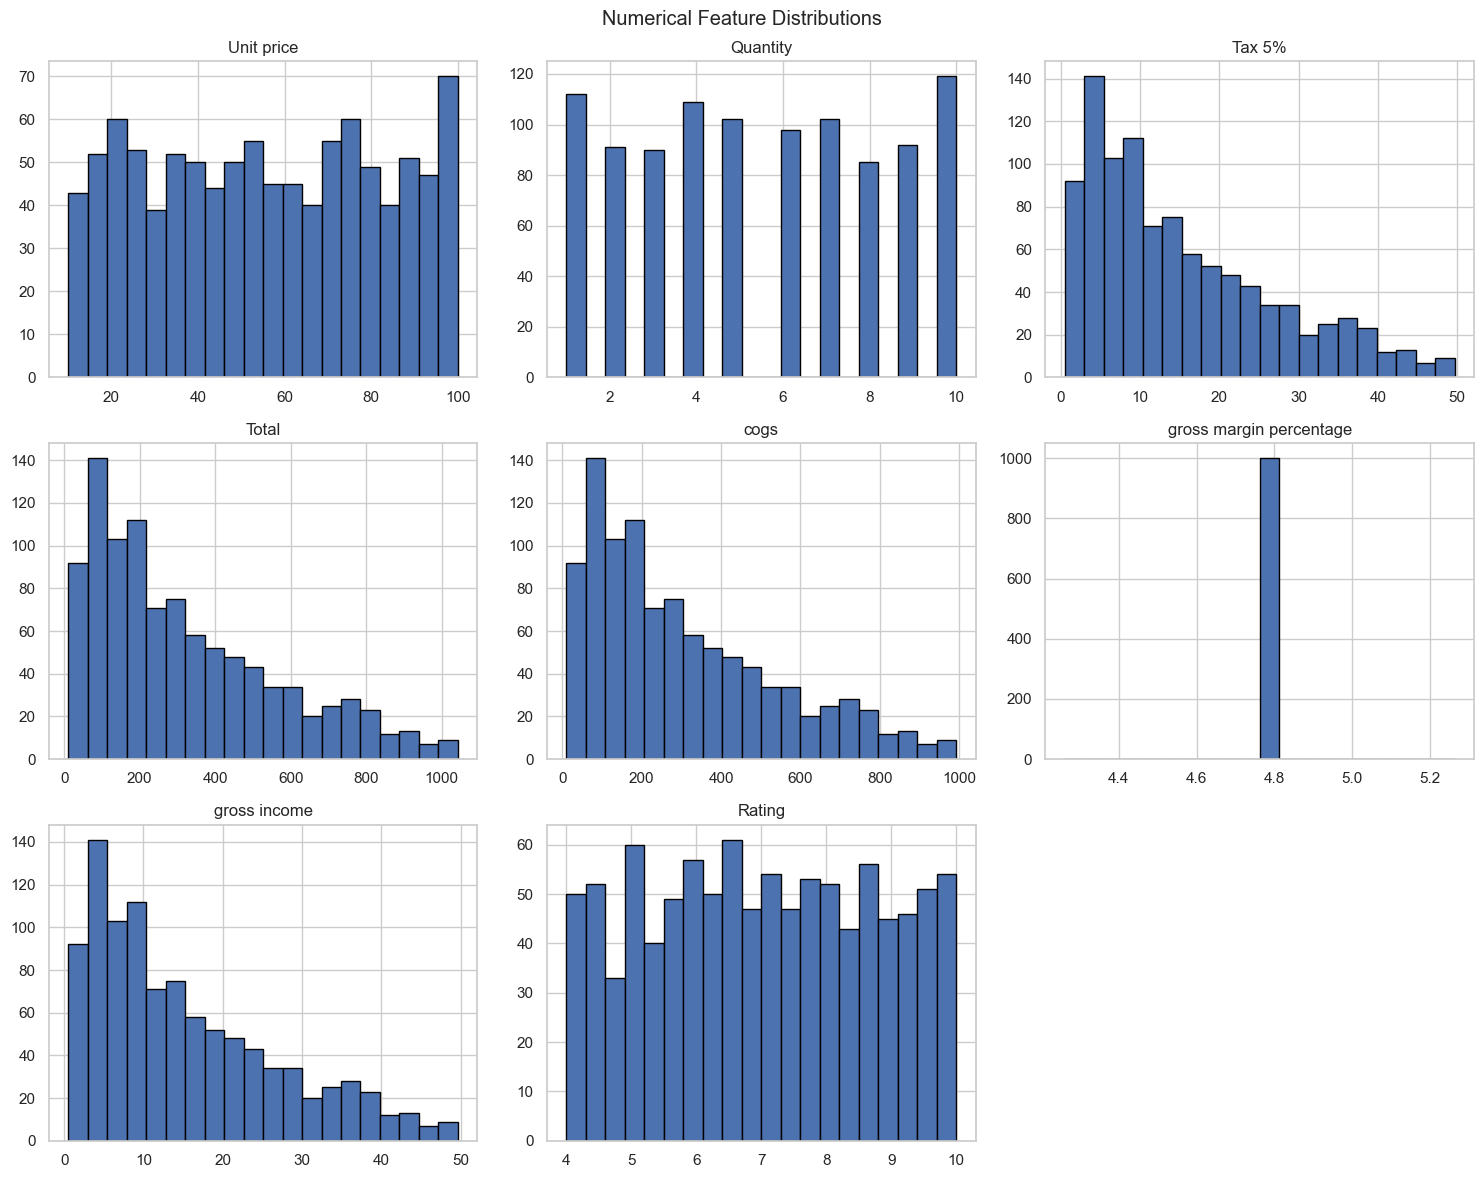


Outlier Analysis:


,Feature,Lower Limit,Upper Limit,Outlier Count
0,Unit price,-34.72,145.52,0
1,Quantity,-4.50,15.50,0
2,Tax 5%,-18.86,47.23,9
3,Total,-395.97,991.74,9
4,cogs,-377.11,944.52,9
5,gross margin percentage,4.76,4.76,0
6,gross income,-18.86,47.23,9
7,Rating,1.00,13.00,0


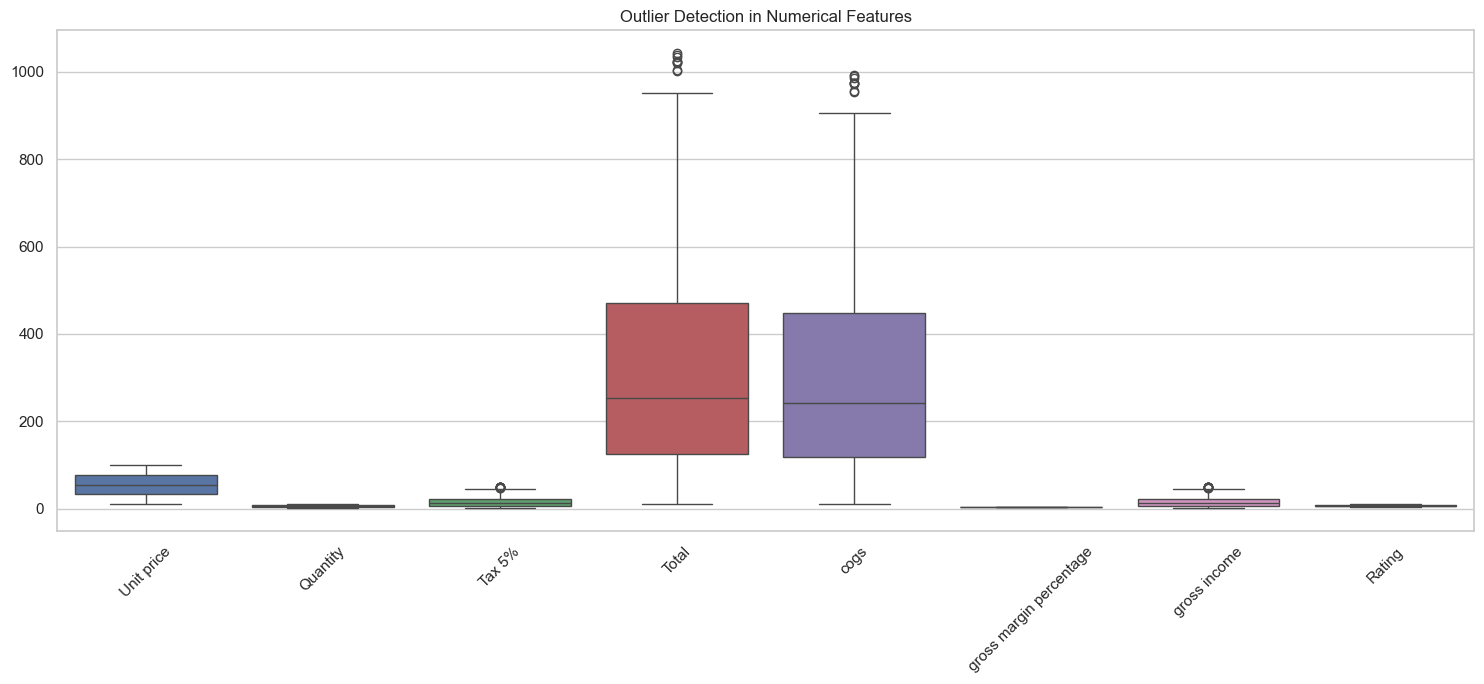


Most Common Categories in Product line:
Product line
Fashion accessories       178
Food and beverages        174
Electronic accessories    170
Sports and travel         166
Home and lifestyle        160
Name: count, dtype: int64

Most Common Categories in Branch:
Branch
A    340
B    332
C    328
Name: count, dtype: int64

Most Common Categories in Customer type:
Customer type
Member    501
Normal    499
Name: count, dtype: int64

Most Common Categories in Payment:
Payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64

Revenue by Product Line:


Product line
Food and beverages        56144.8440
Sports and travel         55122.8265
Electronic accessories    54337.5315
Fashion accessories       54305.8950
Home and lifestyle        53861.9130
Health and beauty         49193.7390
Name: Total, dtype: float64


Revenue by Branch:


Branch
C    110568.7065
A    106200.3705
B    106197.6720
Name: Total, dtype: float64


Average Spending by Customer Type:


Customer type
Member    327.791305
Normal    318.122856
Name: Total, dtype: float64


Transactions by Payment Method:


Payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64


Important Business Features:

1. Product line - Helps identify high-performing product categories.
2. Total - Measures revenue generated per transaction.
3. Branch - Helps compare supermarket branch performance.
4. Quantity - Shows customer purchasing behavior.
5. Customer type - Helps understand customer segments.
6. Payment - Identifies customer payment preferences.
7. Rating - Measures customer satisfaction.



In [10]:
# 1. Separate Numerical and Categorical Features

numerical_columns = df.select_dtypes(include=np.number).columns
categorical_columns = df.select_dtypes(include='object').columns

print("Numerical Features:")
print(numerical_columns.tolist())

print("\nCategorical Features:")
print(categorical_columns.tolist())


# 2. Numerical Feature Analysis

print("\nNumerical Feature Statistics:")
display(df[numerical_columns].describe())


# 3. Minimum, Maximum and Average Values

numerical_summary = pd.DataFrame({
    'Minimum': df[numerical_columns].min(),
    'Maximum': df[numerical_columns].max(),
    'Average': df[numerical_columns].mean()
})

display(numerical_summary.round(2))


# 4. Categorical Feature Analysis

for col in categorical_columns:
    print(f"\n{col} - Unique Categories:")
    print(df[col].unique())

    print(f"\n{col} - Category Counts:")
    print(df[col].value_counts())


# 5. Feature Distributions

df[numerical_columns].hist(
    figsize=(15, 12),
    bins=20,
    edgecolor='black'
)

plt.suptitle("Numerical Feature Distributions")
plt.tight_layout()
plt.show()


# 6. Outlier Detection Using IQR

outlier_summary = []

for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]

    outlier_summary.append({
        'Feature': col,
        'Lower Limit': round(lower_limit, 2),
        'Upper Limit': round(upper_limit, 2),
        'Outlier Count': len(outliers)
    })

outlier_df = pd.DataFrame(outlier_summary)

print("\nOutlier Analysis:")
display(outlier_df)


# 7. Visualize Outliers Using Box Plots

plt.figure(figsize=(15, 7))

sns.boxplot(data=df[numerical_columns])

plt.title("Outlier Detection in Numerical Features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 8. Important Category Analysis

important_categories = ['Product line', 'Branch', 'Customer type', 'Payment']

for col in important_categories:
    print(f"\nMost Common Categories in {col}:")
    print(df[col].value_counts().head())


# 9. Business Feature Analysis

print("\nRevenue by Product Line:")
display(
    df.groupby('Product line')['Total']
    .sum()
    .sort_values(ascending=False)
)

print("\nRevenue by Branch:")
display(
    df.groupby('Branch')['Total']
    .sum()
    .sort_values(ascending=False)
)

print("\nAverage Spending by Customer Type:")
display(
    df.groupby('Customer type')['Total']
    .mean()
    .sort_values(ascending=False)
)

print("\nTransactions by Payment Method:")
display(df['Payment'].value_counts())


# 10. Identify Important Business Features

print("\nImportant Business Features:")
print("""
1. Product line - Helps identify high-performing product categories.
2. Total - Measures revenue generated per transaction.
3. Branch - Helps compare supermarket branch performance.
4. Quantity - Shows customer purchasing behavior.
5. Customer type - Helps understand customer segments.
6. Payment - Identifies customer payment preferences.
7. Rating - Measures customer satisfaction.
""")

## . Identify which features appear to be most important for the business problem 
## represented by your dataset.
### .Quantity.
It has the strongest link to sales: a correlation of about 0.71 with Total, and the highest importance (about 52%) in the Random Forest. Unit price is a close second, but Quantity varies more across customers, so it is the factor the business can influence most, for example through bundles and multi-buy offers.

# 4 . CORRELATION ANALYSIS

Correlation Matrix:


,Unit price,Quantity,Tax 5%,Total,cogs,gross margin percentage,gross income,Rating
Unit price,1.00,0.01,0.63,0.63,0.63,NaN,0.63,-0.01
Quantity,0.01,1.00,0.71,0.71,0.71,NaN,0.71,-0.02
Tax 5%,0.63,0.71,1.00,1.00,1.00,NaN,1.00,-0.04
Total,0.63,0.71,1.00,1.00,1.00,NaN,1.00,-0.04
cogs,0.63,0.71,1.00,1.00,1.00,NaN,1.00,-0.04
gross margin percentage,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gross income,0.63,0.71,1.00,1.00,1.00,NaN,1.00,-0.04
Rating,-0.01,-0.02,-0.04,-0.04,-0.04,NaN,-0.04,1.00


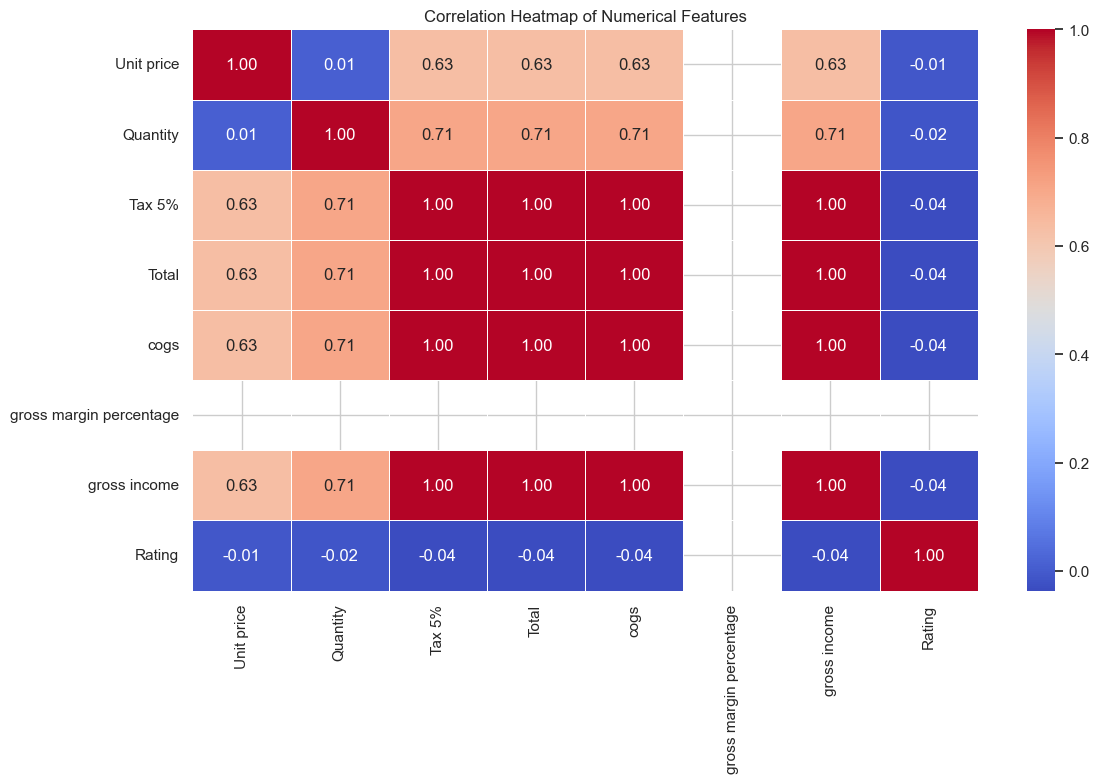


Strong Positive Relationships:
Quantity and Tax 5% : 0.71
Quantity and Total : 0.71
Quantity and cogs : 0.71
Quantity and gross income : 0.71
Tax 5% and Total : 1.0
Tax 5% and cogs : 1.0
Tax 5% and gross income : 1.0
Total and cogs : 1.0
Total and gross income : 1.0
cogs and gross income : 1.0

Strong Negative Relationships:

Weak Relationships:
Unit price and Quantity : 0.01
Unit price and Rating : -0.01
Quantity and Rating : -0.02
Tax 5% and Rating : -0.04
Total and Rating : -0.04
cogs and Rating : -0.04
gross income and Rating : -0.04

Correlation with Total Sales:


,Correlation with Total
Tax 5%,1.00
gross income,1.00
cogs,1.00
Quantity,0.71
Unit price,0.63
Rating,-0.04
gross margin percentage,NaN


In [11]:
# 1. Select Numerical Features

numerical_df = df.select_dtypes(include=np.number)


# 2. Create Correlation Matrix

correlation_matrix = numerical_df.corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))


# 3. Create Correlation Heatmap

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


# 4. Identify Strong Positive Relationships

print("\nStrong Positive Relationships:")

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):
        value = correlation_matrix.iloc[i, j]

        if value >= 0.7:
            print(
                correlation_matrix.columns[i],
                "and",
                correlation_matrix.columns[j],
                ":", round(value, 2)
            )


# 5. Identify Strong Negative Relationships

print("\nStrong Negative Relationships:")

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):
        value = correlation_matrix.iloc[i, j]

        if value <= -0.7:
            print(
                correlation_matrix.columns[i],
                "and",
                correlation_matrix.columns[j],
                ":", round(value, 2)
            )


# 6. Identify Weak Relationships

print("\nWeak Relationships:")

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):
        value = correlation_matrix.iloc[i, j]

        if abs(value) < 0.3:
            print(
                correlation_matrix.columns[i],
                "and",
                correlation_matrix.columns[j],
                ":", round(value, 2)
            )


# 7. Display Important Feature Relationships

print("\nCorrelation with Total Sales:")

display(
    correlation_matrix['Total']
    .drop('Total')
    .sort_values(ascending=False)
    .to_frame(name='Correlation with Total')
    .round(2)
)

# 5 . DATA VISUALIZATION

In [12]:
####Importing important libraries

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

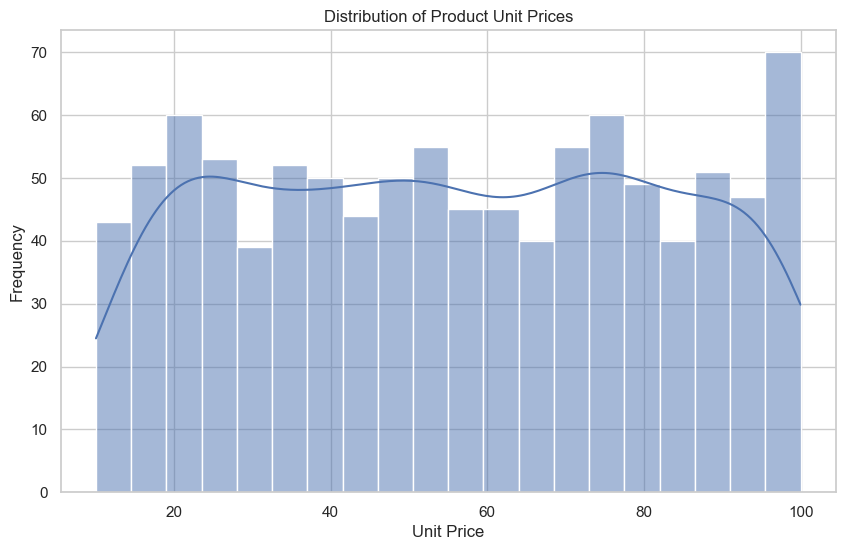

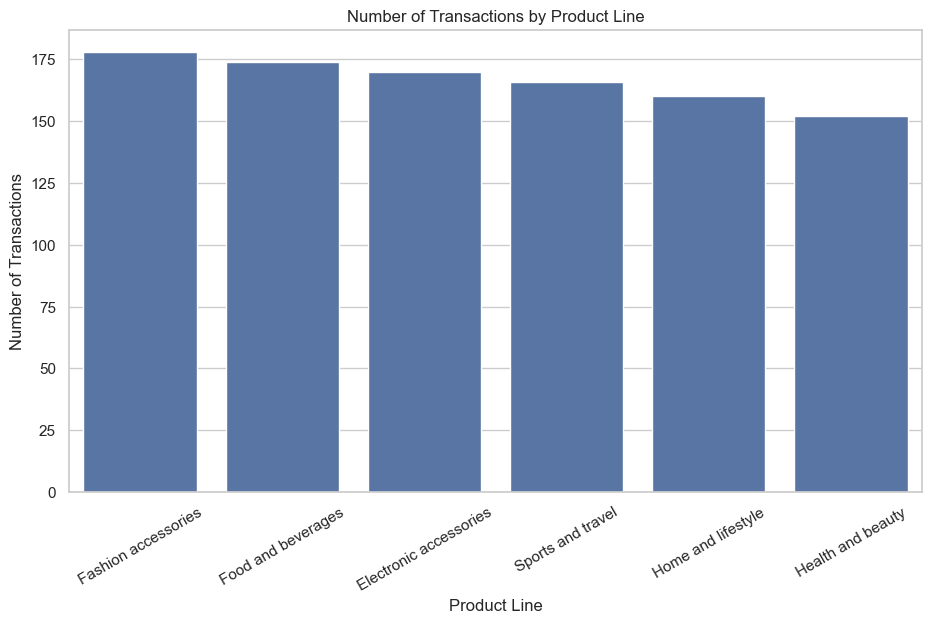

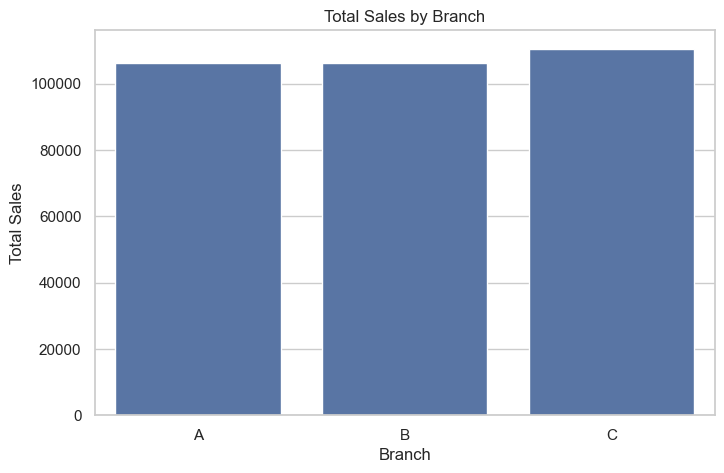

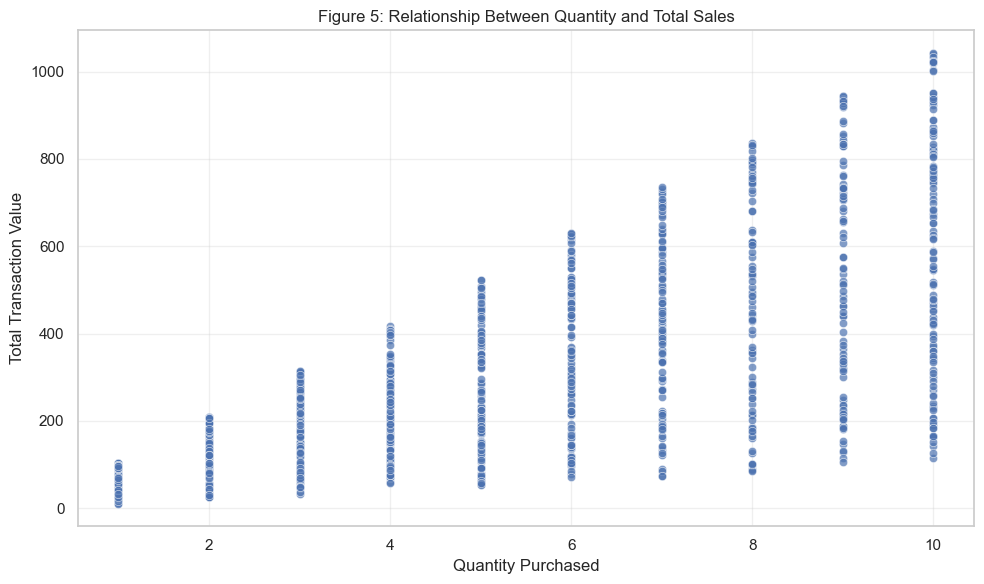

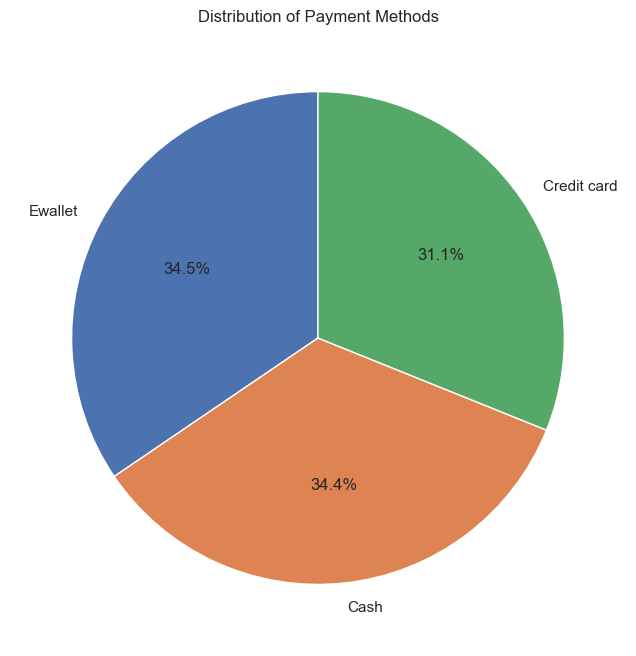

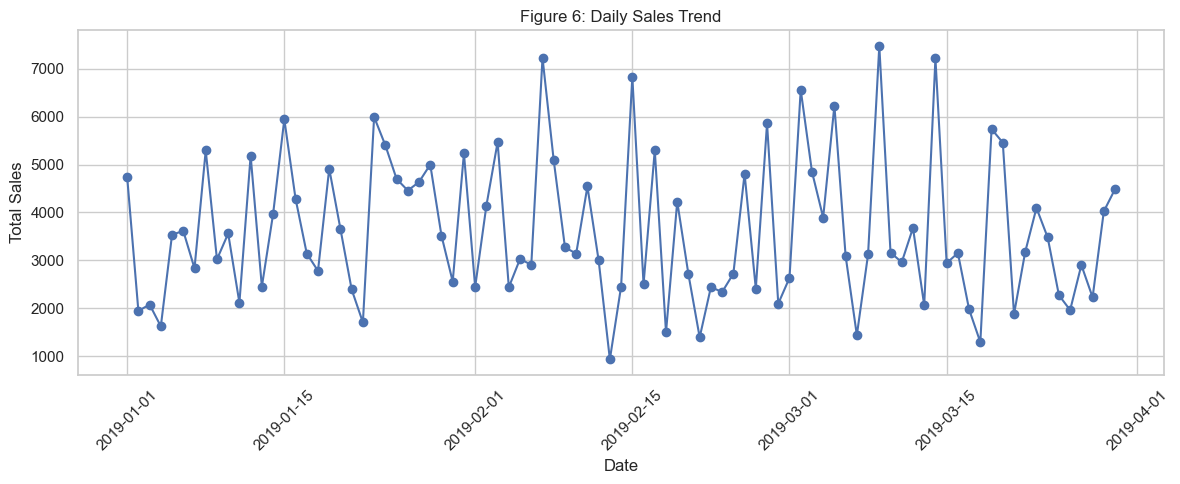

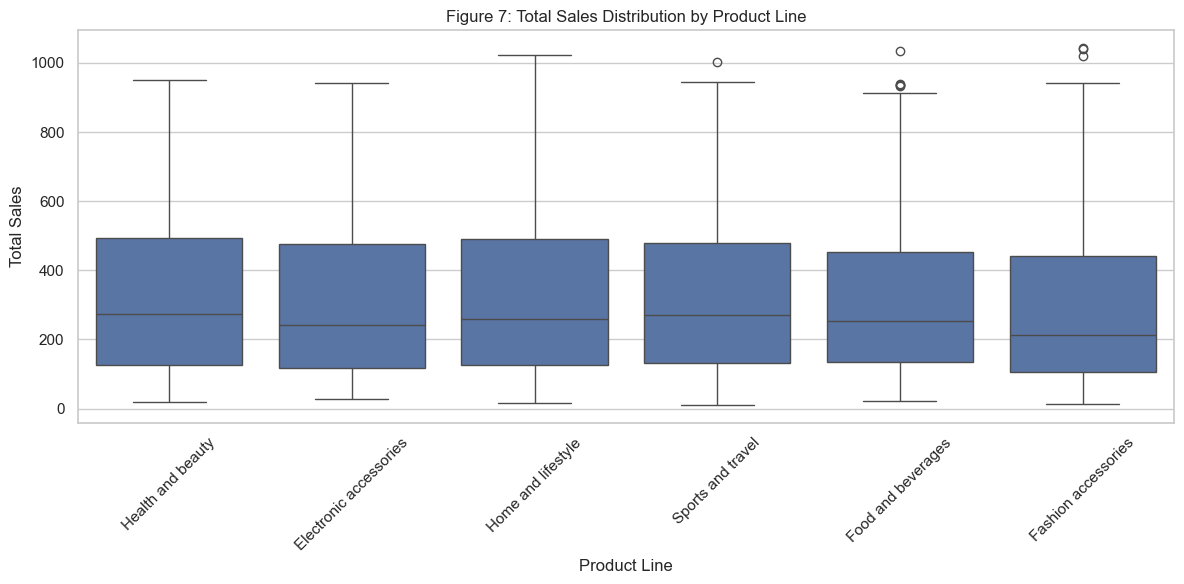

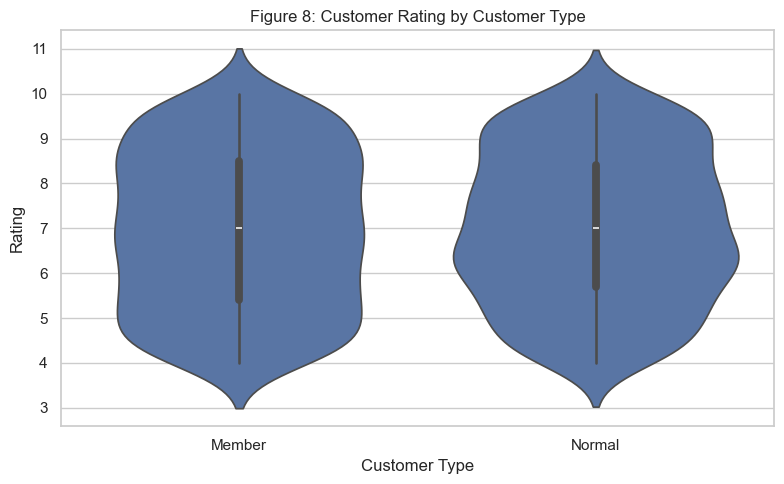

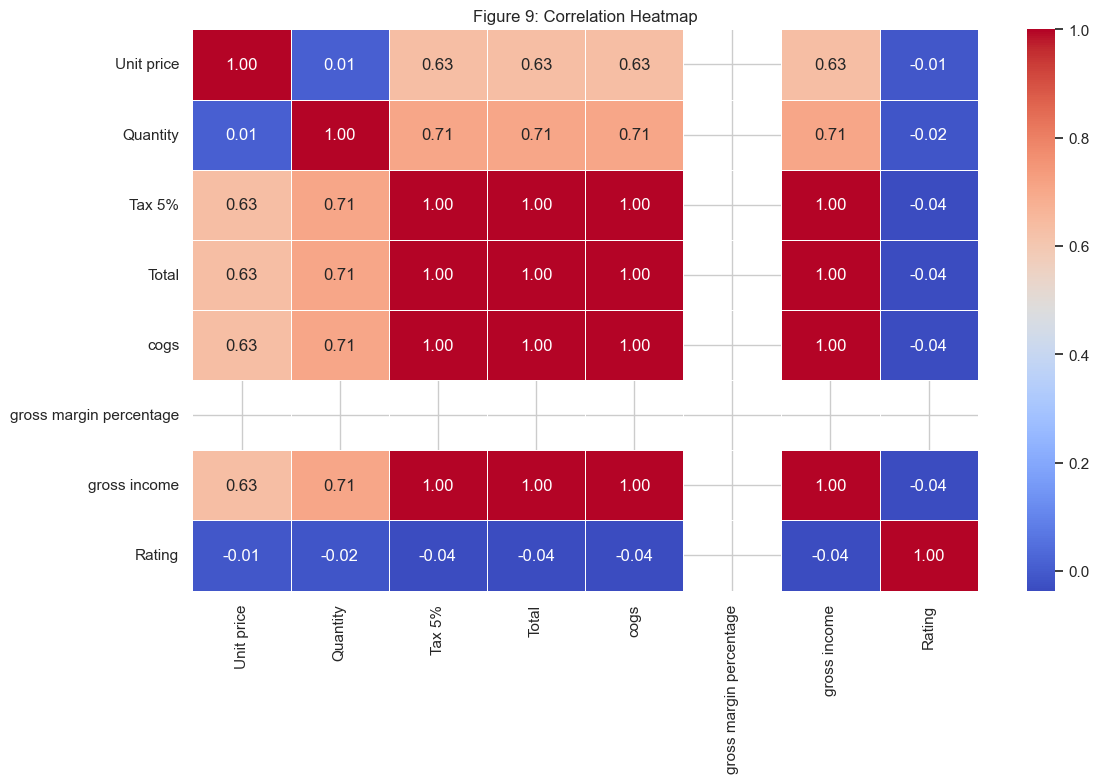

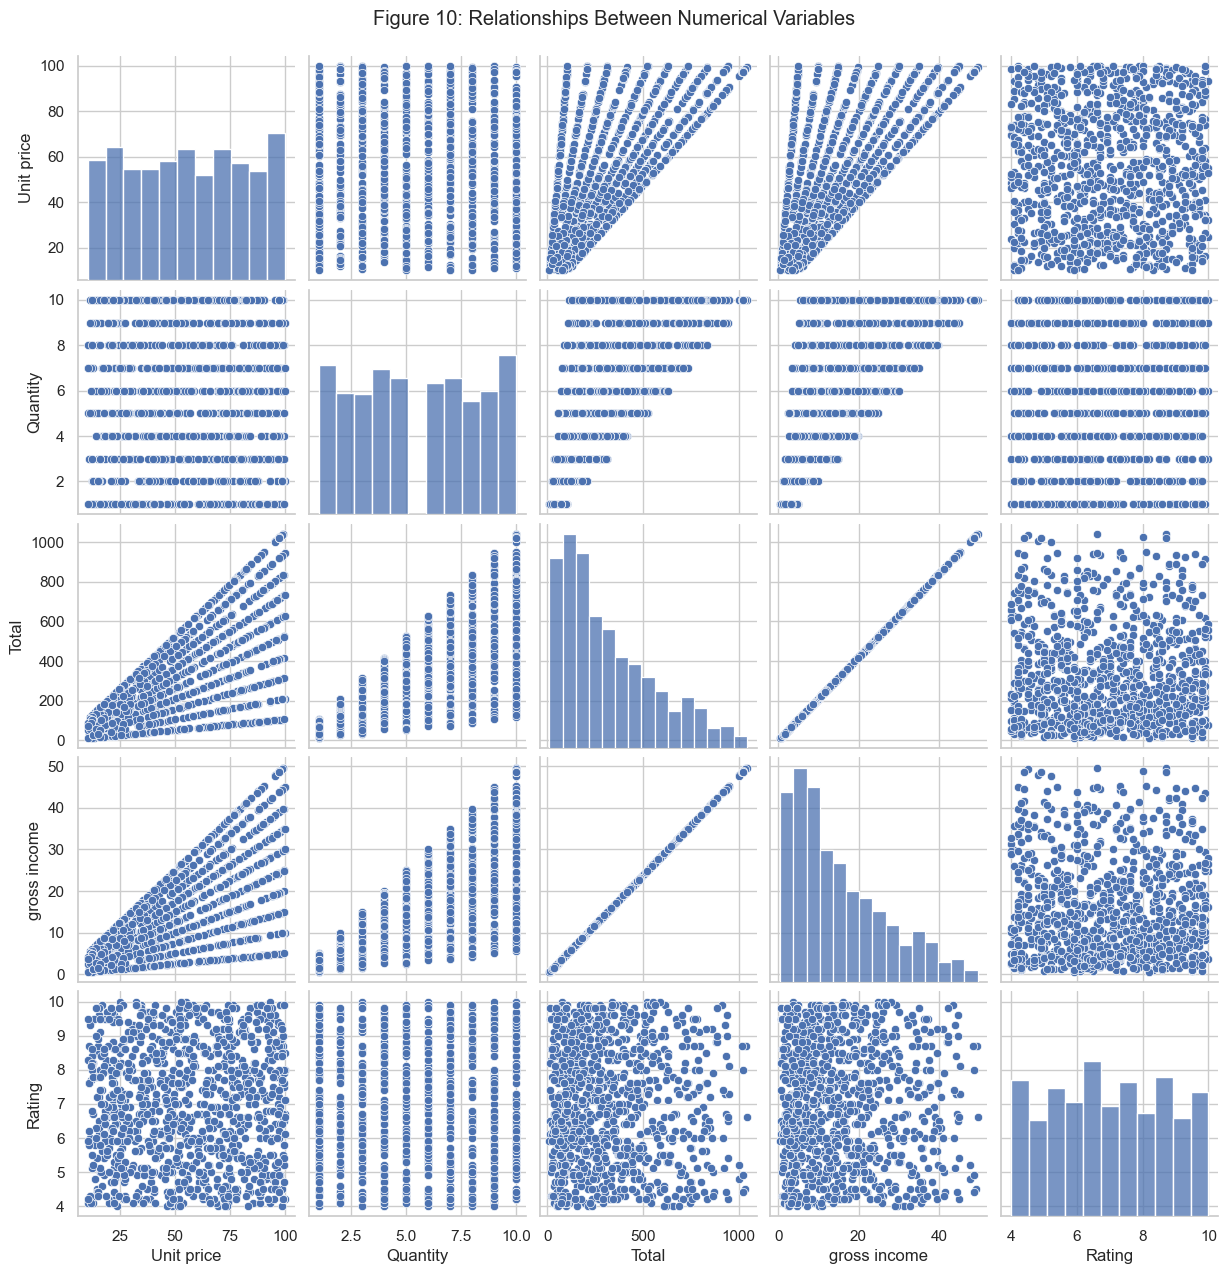

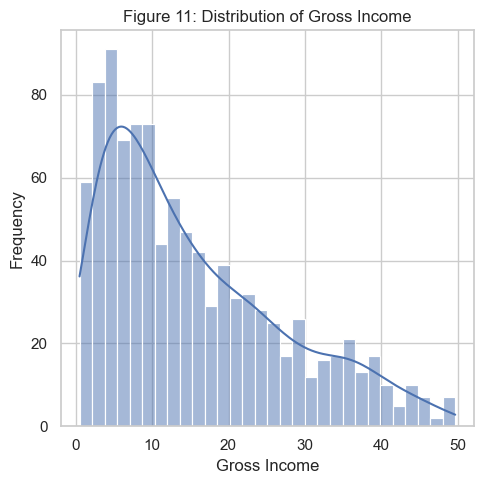

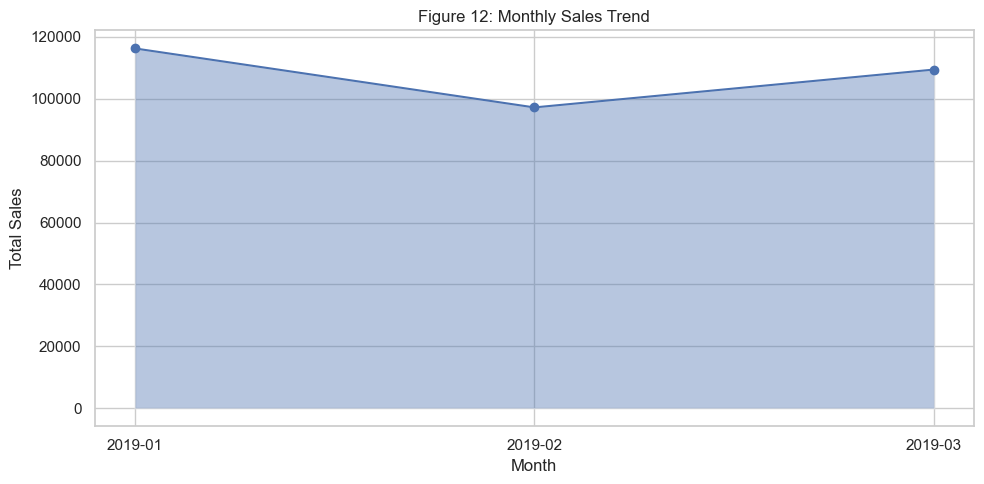

In [18]:
#2. Histogram – Distribution of Unit Price

plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='Unit price', bins=20, kde=True)
plt.title('Distribution of Product Unit Prices')
plt.xlabel('Unit Price')
plt.ylabel('Frequency')
plt.show()

#3.Count Plot – Sales by Product Line

plt.figure(figsize=(11, 6))
sns.countplot(data=df, x='Product line',
              order=df['Product line'].value_counts().index)
plt.title('Number of Transactions by Product Line')
plt.xlabel('Product Line')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=30)
plt.show()

#4. Bar Chart – Total Sales by Branch
#Compares the revenue generated by each supermarket branch.

branch_sales = df.groupby('Branch')['Total'].sum()
plt.figure(figsize=(8, 5))
sns.barplot(x=branch_sales.index, y=branch_sales.values)
plt.title('Total Sales by Branch')
plt.xlabel('Branch')
plt.ylabel('Total Sales')
plt.show()

# Figure 5: Quantity vs Total

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Quantity',
    y='Total',
    alpha=0.7
)

plt.title('Figure 5: Relationship Between Quantity and Total Sales')
plt.xlabel('Quantity Purchased')
plt.ylabel('Total Transaction Value')

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#5. Pie Chart – Payment Methods
#Shows the percentage contribution of each payment method.

payment_counts = df['Payment'].value_counts()
plt.figure(figsize=(8, 8))
plt.pie(payment_counts.values,
        labels=payment_counts.index,
        autopct='%1.1f%%',
        startangle=90)
plt.title('Distribution of Payment Methods')
plt.show()

# Figure 6: Daily Sales Trend
daily_sales = df.groupby('Date')['Total'].sum()

plt.figure(figsize=(12, 5))
plt.plot(daily_sales.index, daily_sales.values, marker='o')
plt.title('Figure 6: Daily Sales Trend')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Figure 7: Total Sales by Product Line (Box Plot)
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='Product line', y='Total')
plt.title('Figure 7: Total Sales Distribution by Product Line')
plt.xlabel('Product Line')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Figure 8: Customer Rating by Customer Type (Violin Plot)
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x='Customer type', y='Rating')
plt.title('Figure 8: Customer Rating by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Rating')
plt.tight_layout()
plt.show()


# Figure 9: Correlation Heatmap
plt.figure(figsize=(12, 8))
correlation = df.select_dtypes(include='number').corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)
plt.title('Figure 9: Correlation Heatmap')
plt.tight_layout()
plt.show()


# Figure 10: Pair Plot
sns.pairplot(
    df[['Unit price', 'Quantity', 'Total', 'gross income', 'Rating']],
    diag_kind='hist'
)
plt.suptitle('Figure 10: Relationships Between Numerical Variables', y=1.02)
plt.show()


# Figure 11: Gross Income Distribution
plt.figure(figsize=(5, 5))
sns.histplot(data=df, x='gross income', kde=True, bins=30)
plt.title('Figure 11: Distribution of Gross Income')
plt.xlabel('Gross Income')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


# Figure 12: Monthly Sales Trend (Area Chart)
monthly_sales = df.groupby(
    df['Date'].dt.to_period('M')
)['Total'].sum()

plt.figure(figsize=(10, 5))
plt.fill_between(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    alpha=0.4
)
plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker='o'
)
plt.title('Figure 12: Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

# . 6 – BUSINESS INSIGHTS

In [15]:

# 1. Sales Performance by Branch
branch_sales = df.groupby('Branch')['Total'].sum()
best_branch = branch_sales.idxmax()
lowest_branch = branch_sales.idxmin()

# 2. Product Line Performance
product_sales = df.groupby('Product line')['Total'].sum()
best_product = product_sales.idxmax()
lowest_product = product_sales.idxmin()

# 3. Quantity Sold by Product Line
product_quantity = df.groupby('Product line')['Quantity'].sum()
most_sold_product = product_quantity.idxmax()

# 4. Customer Type Analysis
customer_sales = df.groupby('Customer type')['Total'].sum()
top_customer_type = customer_sales.idxmax()

# 5. Average Spending by Customer Type
customer_avg = df.groupby('Customer type')['Total'].mean()
highest_spending_customer = customer_avg.idxmax()

# 6. Gender Analysis
gender_sales = df.groupby('Gender')['Total'].sum()
top_gender = gender_sales.idxmax()

# 7. Payment Method Preference
payment_counts = df['Payment'].value_counts()
popular_payment = payment_counts.idxmax()

# 8. Average Customer Rating by Product Line
product_rating = df.groupby('Product line')['Rating'].mean()
highest_rated_product = product_rating.idxmax()
lowest_rated_product = product_rating.idxmin()

# 9. Average Rating
average_rating = df['Rating'].mean()

# 10. Quantity and Total Correlation
quantity_total_corr = df['Quantity'].corr(df['Total'])

# 11. Quantity and Gross Income Correlation
quantity_income_corr = df['Quantity'].corr(df['gross income'])

# 12. Monthly Sales
monthly_sales = df.groupby(
    df['Date'].dt.to_period('M')
)['Total'].sum()
best_month = monthly_sales.idxmax()
lowest_month = monthly_sales.idxmin()

# 13. Average Transaction Value
average_transaction = df['Total'].mean()

# 14. Gross Income by Product Line
product_income = df.groupby('Product line')['gross income'].sum()
highest_income_product = product_income.idxmax()
lowest_income_product = product_income.idxmin()

# 15. Outlier Detection using IQR
Q1 = df['Total'].quantile(0.25)
Q3 = df['Total'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[
    (df['Total'] < lower_bound) |
    (df['Total'] > upper_bound)
]

# Display Business Insights
print("PART 6 – BUSINESS INSIGHTS\n")

print(f"""
1. Branch Performance:
Branch {best_branch} generated the highest total sales
({branch_sales[best_branch]:,.2f}), while Branch {lowest_branch}
generated the lowest ({branch_sales[lowest_branch]:,.2f}).

2. Best Performing Product Line:
{best_product} generated the highest revenue
({product_sales[best_product]:,.2f}).

3. Lowest Performing Product Line:
{lowest_product} generated the lowest revenue
({product_sales[lowest_product]:,.2f}).

4. Product Demand:
{most_sold_product} had the highest total quantity sold
({product_quantity[most_sold_product]} units).

5. Customer Type:
{top_customer_type} customers contributed the highest total sales
({customer_sales[top_customer_type]:,.2f}).

6. Average Customer Spending:
{highest_spending_customer} customers had the highest average
transaction value ({customer_avg[highest_spending_customer]:,.2f}).

7. Gender-Based Sales:
{top_gender} customers contributed the highest total sales
({gender_sales[top_gender]:,.2f}).

8. Payment Preference:
{popular_payment} was the most frequently used payment method
({payment_counts[popular_payment]} transactions).

9. Highest Customer Satisfaction:
{highest_rated_product} had the highest average customer rating
({product_rating[highest_rated_product]:.2f}).

10. Lowest Customer Satisfaction:
{lowest_rated_product} had the lowest average customer rating
({product_rating[lowest_rated_product]:.2f}).

11. Overall Customer Satisfaction:
The average customer rating was {average_rating:.2f} out of 10.

12. Quantity and Sales Relationship:
Quantity and Total had a correlation of {quantity_total_corr:.2f},
indicating a positive relationship between units purchased and
transaction value.

13. Quantity and Gross Income Relationship:
Quantity and gross income had a correlation of
{quantity_income_corr:.2f}, showing how purchase quantity is
associated with gross income.

14. Monthly Revenue Pattern:
{best_month} recorded the highest monthly sales
({monthly_sales[best_month]:,.2f}), while {lowest_month}
recorded the lowest ({monthly_sales[lowest_month]:,.2f}).

15. Transaction Outliers:
There were {len(outliers)} transactions outside the IQR-based
outlier boundaries for Total. These transactions may represent
unusually large or small purchases and should be investigated.
""")


PART 6 – BUSINESS INSIGHTS


1. Branch Performance:
Branch C generated the highest total sales
(110,568.71), while Branch B
generated the lowest (106,197.67).

2. Best Performing Product Line:
Food and beverages generated the highest revenue
(56,144.84).

3. Lowest Performing Product Line:
Health and beauty generated the lowest revenue
(49,193.74).

4. Product Demand:
Electronic accessories had the highest total quantity sold
(971 units).

5. Customer Type:
Member customers contributed the highest total sales
(164,223.44).

6. Average Customer Spending:
Member customers had the highest average
transaction value (327.79).

7. Gender-Based Sales:
Female customers contributed the highest total sales
(167,882.92).

8. Payment Preference:
Ewallet was the most frequently used payment method
(345 transactions).

9. Highest Customer Satisfaction:
Food and beverages had the highest average customer rating
(7.11).

10. Lowest Customer Satisfaction:
Home and lifestyle had the lowest average custo

# . 7 – BUSINESS IMPROVEMENT RECOMMENDATIONS
1. Focus on High-Performing Branches::
Identify the successful strategies of the highest-revenue branch and apply them to lower-performing branches to improve overall sales.

2. Improve Marketing for High-Performing Product Lines::
Invest more in promotions, discounts, and product bundles for product lines generating the highest revenue to increase sales further.

3. Improve Low-Performing Product Categories::
Investigate low-revenue product lines and use targeted discounts, better product placement, and customer feedback to improve their performance.

4. Focus on Customer Spending Behavior::
Use targeted marketing and loyalty programs to encourage high-value customer segments to make repeat purchases and increase spending.

5. Optimize Inventory Based on Product Demand::
Maintain sufficient stock of high-demand products while controlling inventory levels for products with lower sales to reduce storage costs and waste.

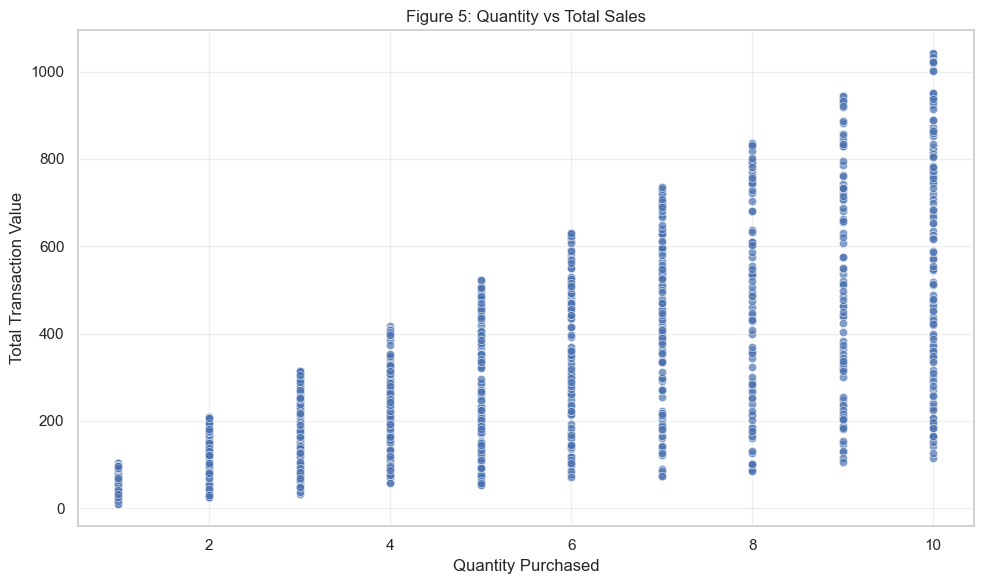

In [19]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x='Quantity', y='Total', alpha=0.7)

plt.title('Figure 5: Quantity vs Total Sales')
plt.xlabel('Quantity Purchased')
plt.ylabel('Total Transaction Value')

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig('Figure_5_Quantity_vs_Total.png', dpi=300, bbox_inches='tight')
plt.show()